EP Ebola: Análise Exploratória de Dados e Data storytelling
Grupo: Ryan Hangai, Ana Luiza Botelho, Arthur Guerra, Michel Domingues e Julio Magno
Disciplina: Exploratory Data Analysis, Prof. Kyung Moo Kim.


Etapa 1: Ingestão, saneamento e auditoria dos dados.

Unidades adotadas: Taxa de letalidade em % e razão de incidência por 100.000 habitantes.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_excel('/content/ebola_historico_africa_subsaariana_2014_2026.xlsx')

# Padroniza os nomes das colunas (sem espaços nas pontas e no meio)
df.columns = df.columns.str.strip().str.replace(' ', '_')

# Confere se sobrou caractere especial ou acento nos nomes
colunas_com_especial = [c for c in df.columns
                        if not (c.replace('_', '').isalnum() and c.isascii())]
print('Colunas com caracteres especiais:', colunas_com_especial)

# Ajuste de tipos
df['Data_Notificacao'] = pd.to_datetime(df['Data_Notificacao'])
df['Dias_Ate_Internacao'] = df['Dias_Ate_Internacao'].astype('Int64')

Colunas com caracteres especiais: []


In [3]:
print('Dimensão:', df.shape)

# Valores ausentes
nulos = df.isnull().sum()
auditoria_nulos = pd.DataFrame({
    'Nulos': nulos,
    'Pct_Nulos': (nulos / len(df) * 100).round(2)
})
display(auditoria_nulos[auditoria_nulos['Nulos'] > 0])

# Duplicados
print('IDs duplicados:', df['ID_Registro'].duplicated().sum())
print('Linhas duplicadas:', df.duplicated().sum())

# Consistência dos valores
print('Letalidade fora de 0-100%:',
      ((df['Taxa_Letalidade_Pct'] < 0) | (df['Taxa_Letalidade_Pct'] > 100)).sum())
print('Idades negativas:', (df['Idade_Paciente'] < 0).sum())
print('Dias até internação negativos:', (df['Dias_Ate_Internacao'] < 0).sum())
print('Casos negativos:', (df['Casos_Confirmados_Semana'] < 0).sum())
print('Ano diferente do ano da data:',
      (df['Data_Notificacao'].dt.year != df['Ano']).sum())
print('Período dos dados:', df['Data_Notificacao'].min().date(),
      'a', df['Data_Notificacao'].max().date())

Dimensão: (1200, 10)


,Nulos,Pct_Nulos
Dias_Ate_Internacao,84,7.0
Leitos_Por_10k_Hab,60,5.0


IDs duplicados: 0
Linhas duplicadas: 0
Letalidade fora de 0-100%: 0
Idades negativas: 0
Dias até internação negativos: 0
Casos negativos: 0
Ano diferente do ano da data: 0
Período dos dados: 2014-01-01 a 2026-09-30


In [4]:
# Marca as linhas imputadas (a regressão da Etapa 3 precisa saber quais são)
df['Dias_Imputado'] = df['Dias_Ate_Internacao'].isnull()
df['Leitos_Imputado'] = df['Leitos_Por_10k_Hab'].isnull()

# Mediana: não é puxada por valores extremos
mediana_dias = int(df['Dias_Ate_Internacao'].median())
mediana_leitos = df['Leitos_Por_10k_Hab'].median()

df['Dias_Ate_Internacao'] = df['Dias_Ate_Internacao'].fillna(mediana_dias)
df['Leitos_Por_10k_Hab'] = df['Leitos_Por_10k_Hab'].fillna(mediana_leitos)

print('Linhas imputadas em Dias_Ate_Internacao:', df['Dias_Imputado'].sum())
print('Linhas imputadas em Leitos_Por_10k_Hab:', df['Leitos_Imputado'].sum())
print('Nulos restantes:', df.isnull().sum().sum())

Linhas imputadas em Dias_Ate_Internacao: 84
Linhas imputadas em Leitos_Por_10k_Hab: 60
Nulos restantes: 0


,Coluna,Outliers (IQR),Limite Inf (IQR),Limite Sup (IQR),Outliers (Z-score > 3)
0,Idade_Paciente,8,-6.00,74.00,5
1,Dias_Ate_Internacao,23,0.00,8.00,3
2,R0_Local_Estimado,11,0.83,2.83,2
3,Leitos_Por_10k_Hab,13,3.10,21.50,6
4,Casos_Confirmados_Semana,11,54.12,155.12,2
5,Taxa_Letalidade_Pct,10,34.35,79.48,2


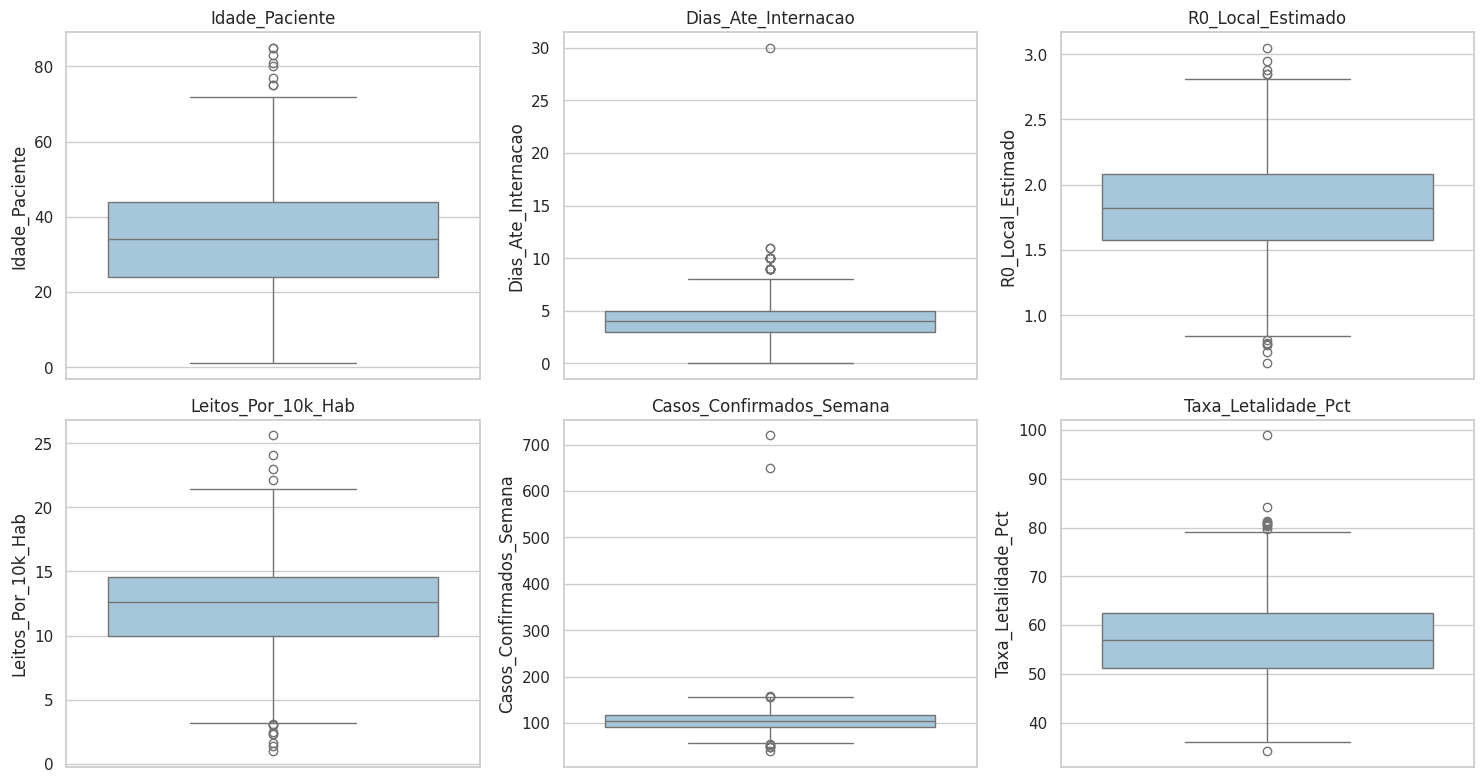

In [5]:
colunas_numericas = ['Idade_Paciente', 'Dias_Ate_Internacao', 'R0_Local_Estimado',
                     'Leitos_Por_10k_Hab', 'Casos_Confirmados_Semana', 'Taxa_Letalidade_Pct']
resumo_outliers = []

for col in colunas_numericas:
    serie = df[col].astype(float)

    # IQR
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    n_iqr = ((serie < limite_inf) | (serie > limite_sup)).sum()

    # Z-score
    z = np.abs(stats.zscore(serie))
    n_z = (z > 3).sum()

    resumo_outliers.append({
        'Coluna': col,
        'Outliers (IQR)': n_iqr,
        'Limite Inf (IQR)': round(limite_inf, 2),
        'Limite Sup (IQR)': round(limite_sup, 2),
        'Outliers (Z-score > 3)': n_z
    })

display(pd.DataFrame(resumo_outliers))

# Boxplots para visualizar os outliers
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), colunas_numericas):
    sns.boxplot(y=df[col].astype(float), ax=ax, color='#9ecae1')
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Valores ausentes:** Os nulos de Dias_Ate_Internacao (84 registros, 7,0%) e Leitos_Por_10k_Hab (60 registros, 5,0%) foram imputados pela mediana, que não é afetada pelos valores extremos que a coluna apresenta. As linhas imputadas ficam marcadas em Dias_Imputado e Leitos_Imputado.

**Outliers:** foram detectados por IQR e Z-score e mantidos, pois representam valores extremos plausíveis em surtos de Ebola, e não erros de registro. As checagens de consistência não encontraram valores impossíveis (ver auditoria).

In [6]:
# Ordena por data
df = df.sort_values('Data_Notificacao').reset_index(drop=True)

# 1) Óbitos estimados: o dataset traz a letalidade em % (por cem),
# então os óbitos são letalidade/100 x casos da semana
df['Obitos_Estimados_Semana'] = (df['Taxa_Letalidade_Pct'] / 100) * df['Casos_Confirmados_Semana']

# 2) Razão de incidência por 100.000 habitantes
# Fonte: Banco Mundial, World Development Indicators, população total 2024 (via FRED)
populacao_2024 = {
    'Serra Leoa': 8642022,
    'Guiné': 14754785,
    'Libéria': 5612817,
    'RDC (Congo)': 109276265,
    'Nigéria': 232679478,
    'Mali': 24478595,
    'Uganda': 50015092
}
df['Populacao_2024'] = df['Pais'].map(populacao_2024)
print('Registros sem população:', df['Populacao_2024'].isnull().sum())

df['Razao_Incidencia_100k'] = df['Casos_Confirmados_Semana'] / df['Populacao_2024'] * 100000

# 3) Médias móveis de contágio com janela de TEMPO (7 e 14 dias)
print('Datas repetidas:', df['Data_Notificacao'].duplicated().sum())

serie_geral = df.groupby('Data_Notificacao')['Casos_Confirmados_Semana'].sum()
media_7d = serie_geral.rolling('7D').mean()
media_14d = serie_geral.rolling('14D').mean()

df['Media_Movel_Contagio_7d'] = df['Data_Notificacao'].map(media_7d)
df['Media_Movel_Contagio_14d'] = df['Data_Notificacao'].map(media_14d)

display(df[['Data_Notificacao', 'Pais', 'Casos_Confirmados_Semana', 'Taxa_Letalidade_Pct',
            'Obitos_Estimados_Semana', 'Razao_Incidencia_100k',
            'Media_Movel_Contagio_7d', 'Media_Movel_Contagio_14d']].head(10))

Registros sem população: 0
Datas repetidas: 0


,Data_Notificacao,Pais,Casos_Confirmados_Semana,Taxa_Letalidade_Pct,Obitos_Estimados_Semana,Razao_Incidencia_100k,Media_Movel_Contagio_7d,Media_Movel_Contagio_14d
0,2014-01-01,Guiné,39,68.32,26.6448,0.264321,39.0,39.00
1,2014-01-04,Serra Leoa,117,67.52,78.9984,1.353850,78.0,78.00
2,2014-01-08,Mali,105,58.32,61.2360,0.428946,111.0,87.00
3,2014-01-12,Guiné,105,63.09,66.2445,0.711634,105.0,91.50
4,2014-01-16,Serra Leoa,88,59.09,51.9992,1.018280,96.5,103.75
5,2014-01-20,Uganda,105,55.14,57.8970,0.209937,96.5,100.75
6,2014-01-24,Guiné,92,74.90,68.9080,0.623527,98.5,97.50
7,2014-01-28,RDC (Congo),102,59.84,61.0368,0.093341,97.0,96.75
8,2014-02-01,Serra Leoa,158,44.50,70.3100,1.828276,130.0,114.25
9,2014-02-04,Libéria,83,62.32,51.7256,1.478758,120.5,108.75


**Fonte da população:** Banco Mundial, World Development Indicators, indicador "Population, total" (SP.POP.TOTL), consultado via FRED (Federal Reserve Bank of St. Louis) em 22/10/2026. Séries: POPTOTSLA647NWDB (Serra Leoa), POPTOTGNA647NWDB (Guiné), POPTOTLRA647NWDB (Libéria), POPTOTCDA647NWDB (RDC), POPTOTNGA647NWDB (Nigéria), POPTOTMLA647NWDB (Mali) e POPTOTUGA647NWDB (Uganda). https://fred.stlouisfed.org

**Limitações:**
1. Usamos a população de 2024 para todo o período 2014–2026, o que é uma simplificação, pois a população cresce ao longo dos anos.
2. A razão de incidência é semanal: Casos confirmados na semana por 100.000 habitantes.
3. Os registros são espaçados (cerca de um a cada 4 dias, de países diferentes), então as médias móveis de 7 e 14 dias têm poucos pontos por janela.
4. Os óbitos são estimados a partir da letalidade e dos casos semanais, não observados diretamente.

5: O dataset não traz densidade populacional; usamos a população total e os leitos por 10 mil habitantes como variáveis socioeconômicas disponíveis. A correlação entre incidência e população (−0,58) é consequência do cálculo (a incidência é dividida pela população) e não deve ser lida como achado.

In [7]:
print('Dimensão final:', df.shape)
print('Nulos restantes:', df.isnull().sum().sum())
display(df[['Obitos_Estimados_Semana', 'Razao_Incidencia_100k',
            'Media_Movel_Contagio_7d', 'Media_Movel_Contagio_14d']].describe().round(2))

Dimensão final: (1200, 17)
Nulos restantes: 0


,Obitos_Estimados_Semana,Razao_Incidencia_100k,Media_Movel_Contagio_7d,Media_Movel_Contagio_14d
count,1200.00,1200.00,1200.00,1200.00
mean,60.34,1.02,105.40,105.37
std,20.81,0.72,22.06,15.92
min,26.42,0.03,39.00,39.00
25%,50.16,0.59,95.00,97.75
50%,58.66,0.98,104.50,104.75
75%,68.61,1.46,113.50,111.06
max,451.04,12.83,437.00,277.50


Etapa 2: Análise exploratória e visualização de dados
Análise temporal e tendências

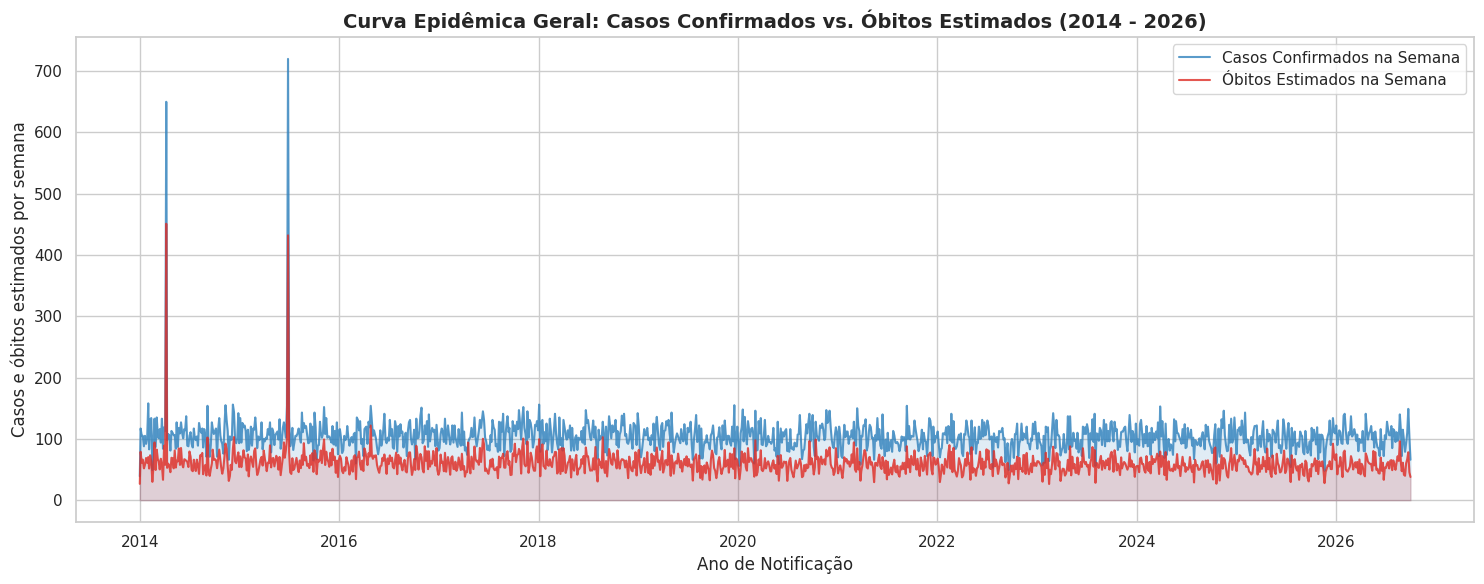

In [8]:
# Agrupa por data para ter a visão global da linha do tempo
df_temporal = df.groupby('Data_Notificacao').agg({
    'Casos_Confirmados_Semana': 'sum',
    'Media_Movel_Contagio_7d': 'first',
    'Media_Movel_Contagio_14d': 'first',
    'Obitos_Estimados_Semana': 'sum'
}).reset_index()

# Gráfico 1: curva epidêmica (casos confirmados e óbitos estimados)
plt.figure(figsize=(15, 6))

# Casos confirmados
plt.plot(df_temporal['Data_Notificacao'], df_temporal['Casos_Confirmados_Semana'],
         label='Casos Confirmados na Semana', color='#3182bd', alpha=0.8, linewidth=1.5)
plt.fill_between(df_temporal['Data_Notificacao'], df_temporal['Casos_Confirmados_Semana'],
                 color='#3182bd', alpha=0.15)

# Óbitos estimados
plt.plot(df_temporal['Data_Notificacao'], df_temporal['Obitos_Estimados_Semana'],
         label='Óbitos Estimados na Semana', color='#de2d26', alpha=0.8, linewidth=1.5)
plt.fill_between(df_temporal['Data_Notificacao'], df_temporal['Obitos_Estimados_Semana'],
                 color='#de2d26', alpha=0.15)

plt.title('Curva Epidêmica Geral: Casos Confirmados vs. Óbitos Estimados (2014 - 2026)',
          fontsize=14, fontweight='bold')
plt.xlabel('Ano de Notificação', fontsize=12)
plt.ylabel('Casos e óbitos estimados por semana', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

**Curva epidêmica:** entre 2014 e 2026 a notificação semanal se mantém estável em torno de 100 casos e 60 óbitos estimados, sem tendência de crescimento ou queda. Há dois picos agudos, no início de 2014 e em meados de 2015, com cerca de 650 e 700 casos em uma única semana. Para a gestão, isso indica uma doença endêmica constante, com risco de surtos súbitos que exigem capacidade de resposta rápida.

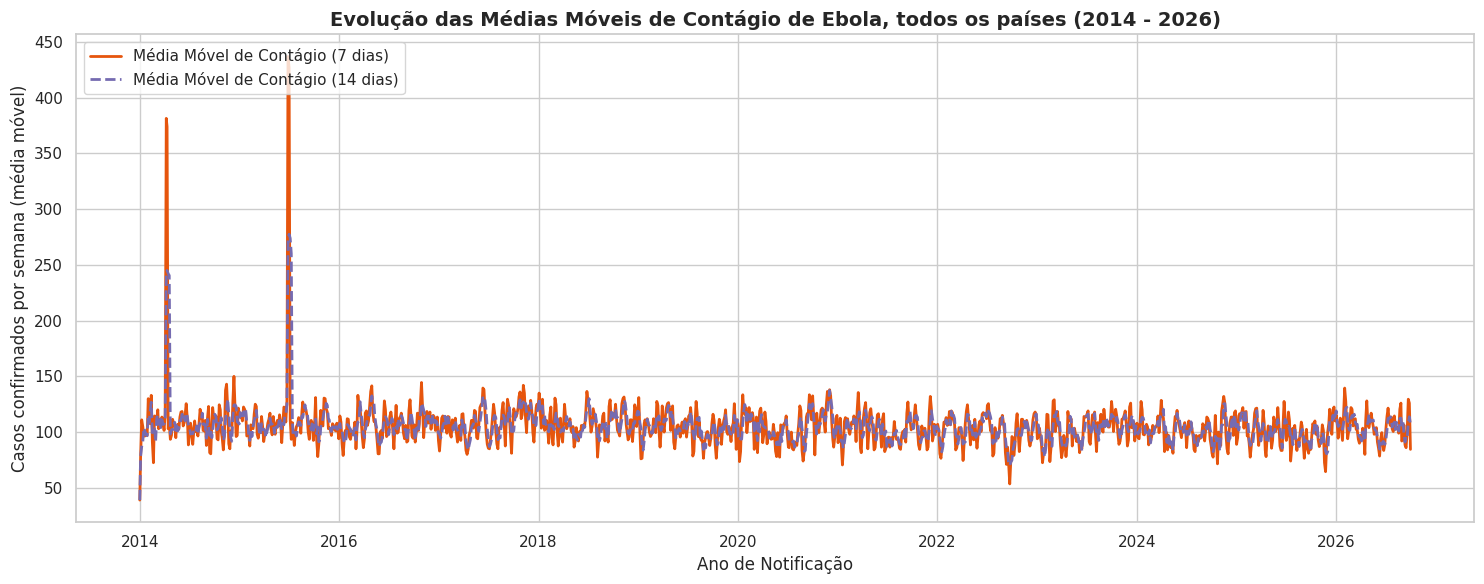

In [9]:
# Gráfico 2: médias móveis de contágio (7 e 14 dias), todos os países
plt.figure(figsize=(15, 6))

plt.plot(df_temporal['Data_Notificacao'], df_temporal['Media_Movel_Contagio_7d'],
         label='Média Móvel de Contágio (7 dias)', color='#e6550d', linewidth=2)
plt.plot(df_temporal['Data_Notificacao'], df_temporal['Media_Movel_Contagio_14d'],
         label='Média Móvel de Contágio (14 dias)', color='#756bb1', linewidth=2, linestyle='--')

plt.title('Evolução das Médias Móveis de Contágio de Ebola, todos os países (2014 - 2026)',
          fontsize=14, fontweight='bold')
plt.xlabel('Ano de Notificação', fontsize=12)
plt.ylabel('Casos confirmados por semana (média móvel)', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

Análise geoespacial e comparativa
Comparação do impacto da doença por país. A letalidade ponderada é o total de óbitos estimados dividido pelo total de casos, em % ("por cem"), como na definição do enunciado (mortes / casos confirmados).

In [10]:
# Agrupa os dados por país para analisar o impacto regional
df_impacto_pais = df.groupby('Pais').agg(
    Total_Casos=('Casos_Confirmados_Semana', 'sum'),
    Total_Obitos_Estimados=('Obitos_Estimados_Semana', 'sum'),
    Letalidade_Media_Pct=('Taxa_Letalidade_Pct', 'mean'),
    Incidencia_Media_100k=('Razao_Incidencia_100k', 'mean'),
    Media_Leitos_10k=('Leitos_Por_10k_Hab', 'mean'),
    Populacao_2024=('Populacao_2024', 'first')
).reset_index().sort_values(by='Total_Casos', ascending=False)

# Letalidade ponderada pelos casos: óbitos / casos x 100
df_impacto_pais['Letalidade_Ponderada_Pct'] = (
    df_impacto_pais['Total_Obitos_Estimados'] / df_impacto_pais['Total_Casos'] * 100
)

# Tabela consolidada
display(df_impacto_pais.round(2))

,Pais,Total_Casos,Total_Obitos_Estimados,Letalidade_Media_Pct,Incidencia_Media_100k,Media_Leitos_10k,Populacao_2024,Letalidade_Ponderada_Pct
5,Serra Leoa,38452,22030.29,57.29,1.22,12.52,8642022,57.29
0,Guiné,31825,18056.54,56.72,0.70,11.94,14754785,56.74
1,Libéria,29806,17090.36,57.46,1.88,12.32,5612817,57.34
4,RDC (Congo),15042,8645.83,57.58,0.10,12.52,109276265,57.48
3,Nigéria,5447,3102.85,56.83,0.04,12.97,232679478,56.96
2,Mali,4080,2396.73,57.35,0.49,13.82,24478595,58.74
6,Uganda,1836,1086.33,58.91,0.22,12.31,50015092,59.17


**Impacto por país:** Serra Leoa (38.452 casos), Guiné (31.825) e Libéria (29.806) concentram a maior parte dos casos. Quando se olha por habitante, a ordem muda: a Libéria tem a maior incidência semanal (1,88 por 100 mil), à frente de Serra Leoa (1,22) e Guiné (0,70), enquanto Nigéria (0,04) e RDC (0,10) caem por terem populações muito grandes. A letalidade é parecida em todos os países (de 56,7% a 59,2%) e os leitos por 10 mil habitantes também (de 11,9 a 13,8), então a diferença entre países vem do volume de casos, não da gravidade.

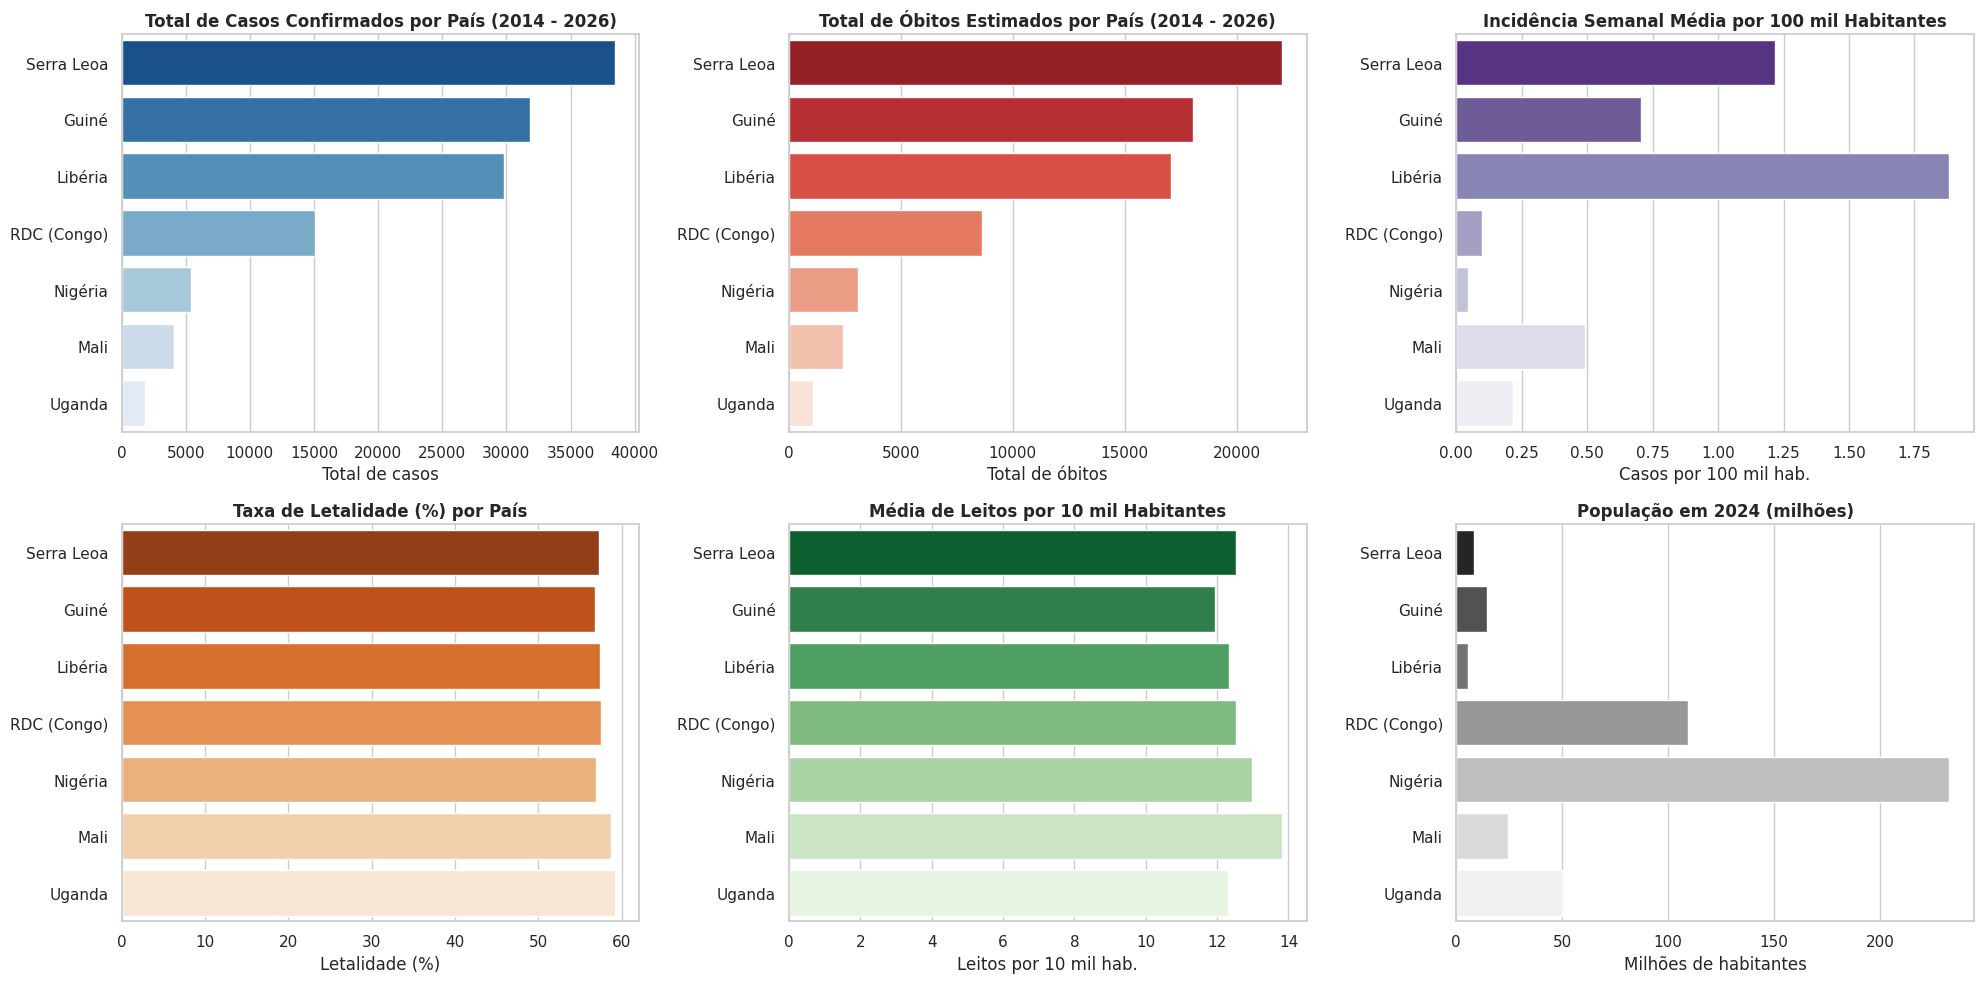

In [11]:
# População em milhões, só para o gráfico ficar legível
df_impacto_pais['Populacao_Milhoes'] = df_impacto_pais['Populacao_2024'] / 1e6

# Cada painel: coluna, título, rótulo do eixo X e paleta
paineis = [
    ('Total_Casos', 'Total de Casos Confirmados por País (2014 - 2026)', 'Total de casos', 'Blues_r'),
    ('Total_Obitos_Estimados', 'Total de Óbitos Estimados por País (2014 - 2026)', 'Total de óbitos', 'Reds_r'),
    ('Incidencia_Media_100k', 'Incidência Semanal Média por 100 mil Habitantes', 'Casos por 100 mil hab.', 'Purples_r'),
    ('Letalidade_Ponderada_Pct', 'Taxa de Letalidade (%) por País', 'Letalidade (%)', 'Oranges_r'),
    ('Media_Leitos_10k', 'Média de Leitos por 10 mil Habitantes', 'Leitos por 10 mil hab.', 'Greens_r'),
    ('Populacao_Milhoes', 'População em 2024 (milhões)', 'Milhões de habitantes', 'Greys_r'),
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))

for ax, (coluna, titulo, rotulo_x, paleta) in zip(axes.flatten(), paineis):
    sns.barplot(ax=ax, data=df_impacto_pais, x=coluna, y='Pais',
                palette=paleta, hue='Pais', legend=False)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

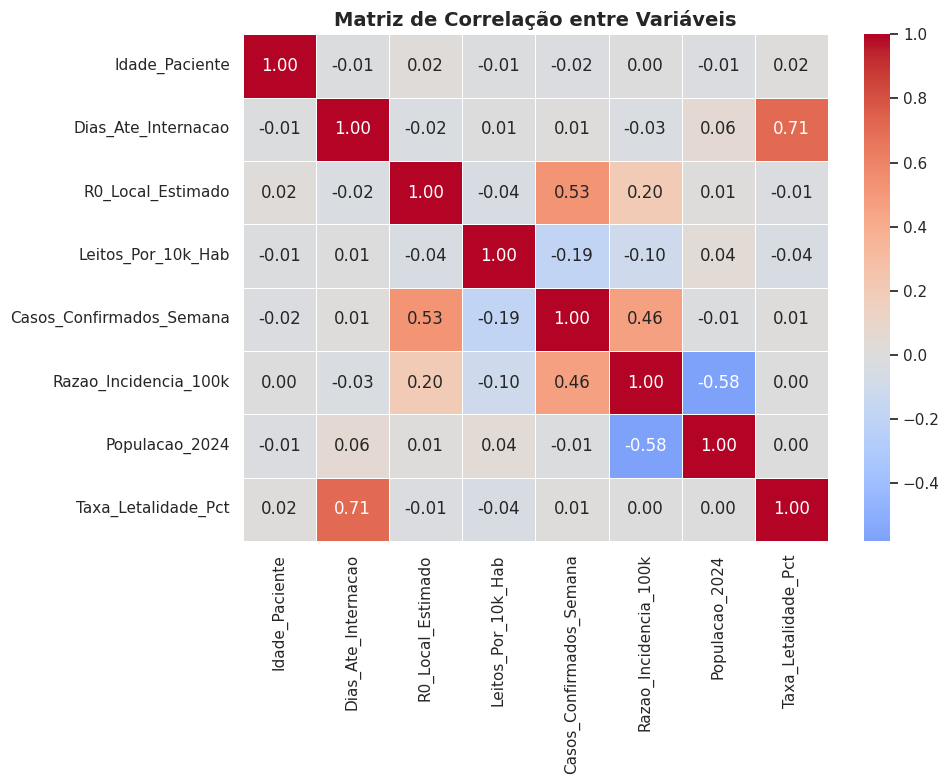

In [12]:
# Matriz de correlação
colunas_corr = ['Idade_Paciente', 'Dias_Ate_Internacao', 'R0_Local_Estimado',
                'Leitos_Por_10k_Hab', 'Casos_Confirmados_Semana',
                'Razao_Incidencia_100k', 'Populacao_2024', 'Taxa_Letalidade_Pct']
corr = df[colunas_corr].astype(float).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de Correlação entre Variáveis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Correlações:** a associação mais forte é entre dias até a internação e letalidade (r = 0,71): quanto maior o atraso, maior a letalidade. O R0 também se associa a mais casos (r = 0,53), e os leitos têm correlação fraca e negativa com os casos (r = −0,19). Idade não se associa a nenhuma variável. A correlação de −0,58 entre incidência e população é consequência do cálculo, não um achado.

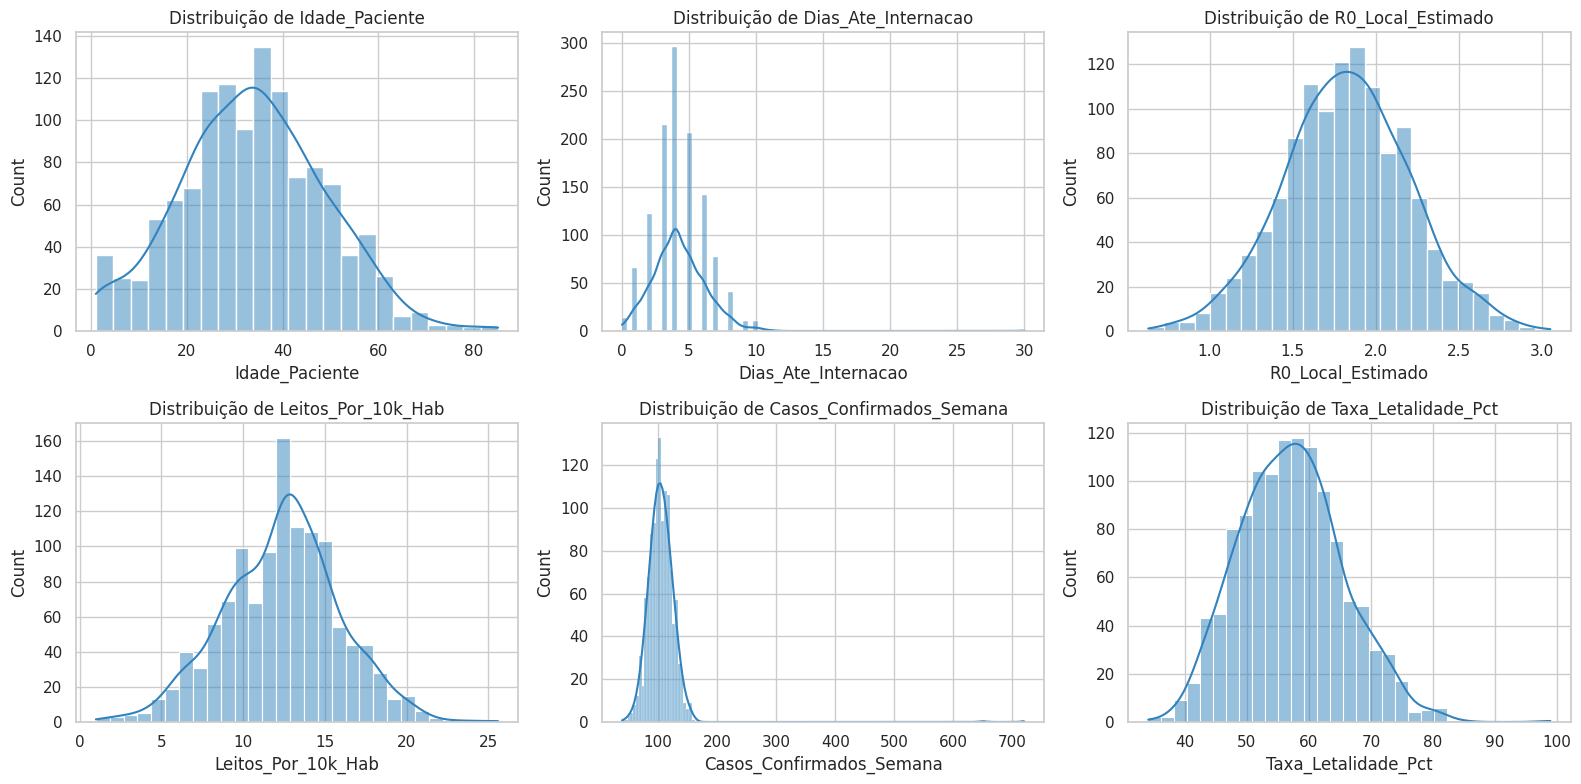

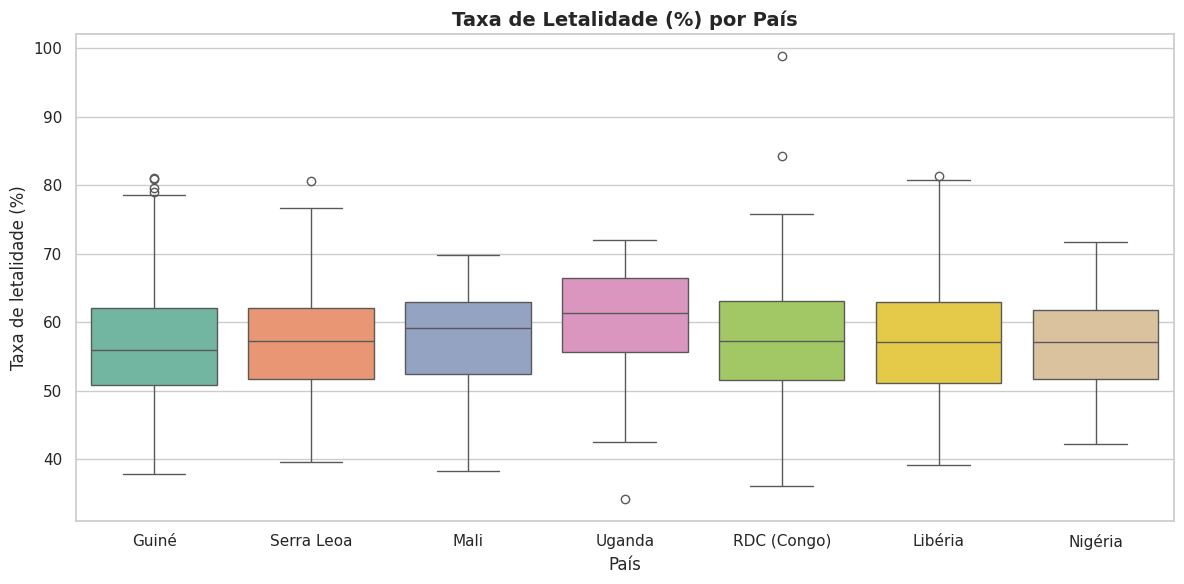

In [13]:
# Distribuições das variáveis numéricas
colunas_dist = ['Idade_Paciente', 'Dias_Ate_Internacao', 'R0_Local_Estimado',
                'Leitos_Por_10k_Hab', 'Casos_Confirmados_Semana', 'Taxa_Letalidade_Pct']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), colunas_dist):
    sns.histplot(df[col].astype(float), kde=True, ax=ax, color='#3182bd')
    ax.set_title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()

# Letalidade por país
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Pais', y='Taxa_Letalidade_Pct', hue='Pais', palette='Set2', legend=False)
plt.title('Taxa de Letalidade (%) por País', fontsize=14, fontweight='bold')
plt.xlabel('País')
plt.ylabel('Taxa de letalidade (%)')
plt.tight_layout()
plt.show()

**Distribuições:** idade, R0, leitos e letalidade têm formato próximo ao de sino. Dias até a internação se concentra entre 3 e 7 dias, com cauda longa até cerca de 30. Casos semanais giram em torno de 100, com poucos valores muito altos. A letalidade é semelhante entre países, com poucos pontos extremos (perto de 85% e 99%).

In [14]:
# 1) Relação dias até internação x letalidade (sem linhas imputadas)
base = df[~df['Dias_Imputado']]
print('Correlação (Pearson):', round(base['Dias_Ate_Internacao'].astype(float).corr(base['Taxa_Letalidade_Pct']), 2))
print('Correlação (Spearman):', round(base['Dias_Ate_Internacao'].astype(float).corr(base['Taxa_Letalidade_Pct'], method='spearman'), 2))
display(base.groupby('Dias_Ate_Internacao')['Taxa_Letalidade_Pct'].agg(['count', 'mean']).round(1))

# 2) Variabilidade da letalidade
letalidade = df['Taxa_Letalidade_Pct']
print('Desvio padrão:', round(letalidade.std(), 2))
print('Coeficiente de variação (%):', round(letalidade.std() / letalidade.mean() * 100, 1))
display(df.groupby('Ano')['Taxa_Letalidade_Pct'].agg(['mean', 'std']).round(1))

# 3) Casos semanais em faixas x letalidade média
faixas = pd.cut(df['Casos_Confirmados_Semana'], bins=[0, 80, 100, 120, 1000])
display(df.groupby(faixas, observed=True)['Taxa_Letalidade_Pct'].agg(['count', 'mean']).round(1))

# 4) Maiores picos de casos e casos por ano e país
display(df.nlargest(5, 'Casos_Confirmados_Semana')[['Data_Notificacao', 'Pais', 'Casos_Confirmados_Semana', 'R0_Local_Estimado']])
display(df.pivot_table(index='Ano', columns='Pais', values='Casos_Confirmados_Semana', aggfunc='sum'))

Correlação (Pearson): 0.74
Correlação (Spearman): 0.81


,count,mean
Dias_Ate_Internacao,,
0,13,43.2
1,66,46.2
2,122,49.0
3,214,52.6
4,212,56.0
5,206,59.7
6,142,63.1
7,77,66.5
8,41,71.0


Desvio padrão: 8.36
Coeficiente de variação (%): 14.6


,mean,std
Ano,,
2014,58.7,8.9
2015,60.0,8.5
2016,59.2,7.9
2017,57.4,9.0
2018,56.8,8.7
2019,57.3,8.7
2020,56.7,8.0
2021,56.9,7.8
2022,56.1,8.8


,count,mean
Casos_Confirmados_Semana,,
"(0, 80]",116,57.4
"(80, 100]",391,57.6
"(100, 120]",460,57.1
"(120, 1000]",233,56.8


,Data_Notificacao,Pais,Casos_Confirmados_Semana,R0_Local_Estimado
140,2015-06-28,Libéria,720,2.01
25,2014-04-08,Mali,650,1.93
8,2014-02-01,Serra Leoa,158,2.85
88,2014-12-08,RDC (Congo),156,2.61
377,2018-01-03,RDC (Congo),156,3.05


Pais,Guiné,Libéria,Mali,Nigéria,RDC (Congo),Serra Leoa,Uganda
Ano,,,,,,,
2014,3228.0,1926.0,965.0,226.0,1127.0,2797.0,385.0
2015,2401.0,3163.0,460.0,753.0,1215.0,2315.0,429.0
2016,3220.0,1918.0,86.0,210.0,1310.0,3157.0,133.0
2017,2520.0,2519.0,91.0,371.0,1546.0,3208.0,NaN
2018,2653.0,2581.0,225.0,881.0,962.0,2667.0,203.0
2019,2254.0,2472.0,360.0,598.0,1364.0,2458.0,233.0
2020,2390.0,1958.0,88.0,384.0,1309.0,3715.0,NaN
2021,2666.0,1692.0,256.0,72.0,1311.0,3594.0,NaN
2022,1894.0,2837.0,212.0,340.0,679.0,3429.0,101.0


Verificações complementares (perguntas levantadas pelo grupo).

Análises extras para responder: (1) qual fator se associa à letalidade, (2) quão variável é a letalidade, (3) se o volume de casos semanais se relaciona com a letalidade e (4) em que anos e países ocorrem os maiores picos.

**Etapa 3: Inferência estatística**

**Teste t de Student: a letalidade mudou entre os períodos?**

**Pergunta:** a taxa de letalidade média de 2014–2019 (período A) é diferente da de 2020–2026 (período B)?

**Variável:** Taxa_Letalidade_Pct (em %, ou seja, "por cem").

**Hipóteses:**
- H0: μA = μB (as médias de letalidade dos dois períodos são iguais)
- H1: μA ≠ μB (as médias são diferentes), teste bilateral

**Nível de significância:** α = 5%.

**Tipo de teste:** duas amostras independentes, pois cada período tem registros diferentes. Foi assumida variância igual entre os períodos (variância combinada), e o cálculo foi feito com a função ttest_ind do StatsModels.


In [15]:
from statsmodels.stats.weightstats import ttest_ind

grupo_a = df[df['Ano'] <= 2019]['Taxa_Letalidade_Pct']
grupo_b = df[df['Ano'] >= 2020]['Taxa_Letalidade_Pct']
t, p_valor, gl = ttest_ind(grupo_a, grupo_b, usevar='pooled')
print(f'média A = {grupo_a.mean():.2f}% | média B = {grupo_b.mean():.2f}% | t = {t:.3f} | p = {p_valor:.4f} | gl = {gl:.0f}')

média A = 58.22% | média B = 56.34% | t = 3.916 | p = 0.0001 | gl = 1198


**Decisão:** como |t| = 3,916 é maior que o t crítico de ±1,96 (gl = 1198), rejeita-se H0 (p < 0,001).

**Conclusão:** há evidência, ao nível de 5%, de que a letalidade média difere entre os períodos: 58,22% em 2014–2019 contra 56,34% em 2020–2026, uma diferença de 1,88 pontos percentuais. Para a saúde pública, isso indica uma leve queda na letalidade ao longo do tempo, mas não prova a causa.